<a href="https://colab.research.google.com/github/utjimmyx/python/blob/main/Battery_life.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

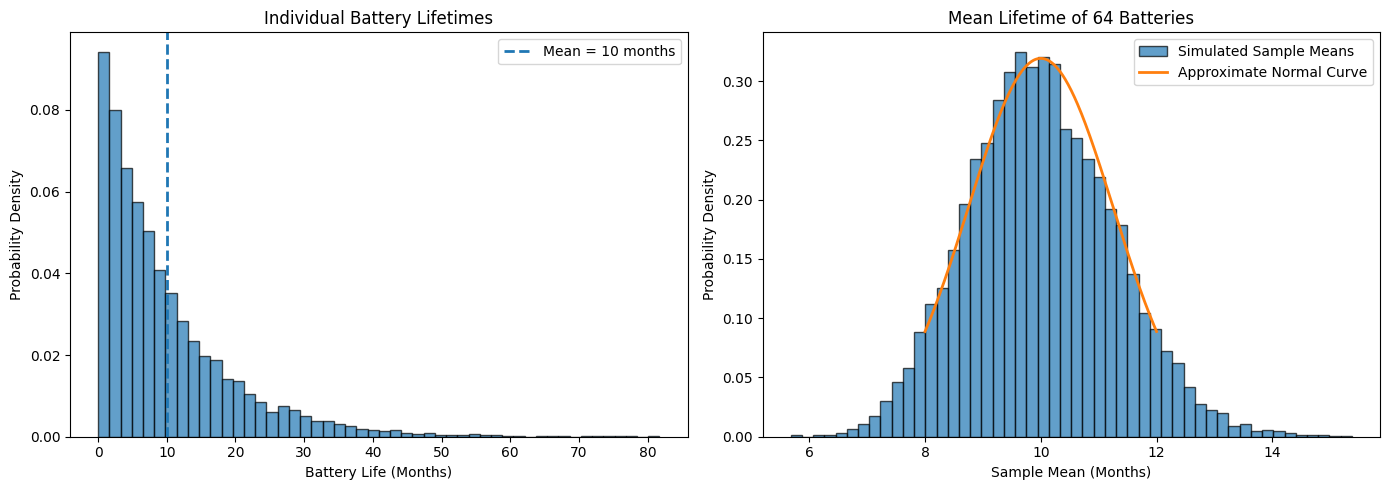

Population mean: 10.00 months
Sample size: 64
Standard error: 1.2500 months
Simulated mean of sample means: 10.0062 months


In [2]:

# You can find my illustrations for Question 12 in Chapter 7 of the book "Business Statistics" here.
## The length of time a particular smartphone's battery lasts
## follows an exponential distribution with a mean of ten months.
## A sample of 64 of these smartphones is taken.
## What is the distribution for the length of time one battery lasts? What distribution does it follow?
## What is the distribution for the mean length of time 64 batteries last? What distribution does it follow?

import numpy as np
import matplotlib.pyplot as plt

# Reproducibility
np.random.seed(42)

# Parameters
population_mean = 10       # months
sample_size = 64
num_simulations = 10000

# Generate individual battery lifetimes (exponential distribution)
battery_lifetimes = np.random.exponential(
    scale=population_mean,
    size=10000
)

# Repeatedly sample 64 batteries and calculate each sample mean
samples = np.random.exponential(
    scale=population_mean,
    size=(num_simulations, sample_size)
)
sample_means = samples.mean(axis=1)

# Theoretical sampling distribution parameters
mean_of_means = population_mean
standard_error = population_mean / np.sqrt(sample_size)

# Create two graphs side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graph 1: Individual battery lifetimes
axes[0].hist(
    battery_lifetimes,
    bins=50,
    density=True,
    alpha=0.7,
    edgecolor="black"
)
axes[0].set_title("Individual Battery Lifetimes")
axes[0].set_xlabel("Battery Life (Months)")
axes[0].set_ylabel("Probability Density")
axes[0].axvline(
    population_mean,
    linestyle="--",
    linewidth=2,
    label="Mean = 10 months"
)
axes[0].legend()

# Graph 2: Sampling distribution of sample means
axes[1].hist(
    sample_means,
    bins=50,
    density=True,
    alpha=0.7,
    edgecolor="black",
    label="Simulated Sample Means"
)

# Overlay the theoretical normal curve
x = np.linspace(8, 12, 300)
normal_curve = (
    1 / (standard_error * np.sqrt(2 * np.pi))
    * np.exp(-0.5 * ((x - mean_of_means) / standard_error) ** 2)
)

axes[1].plot(
    x,
    normal_curve,
    linewidth=2,
    label="Approximate Normal Curve"
)
axes[1].set_title("Mean Lifetime of 64 Batteries")
axes[1].set_xlabel("Sample Mean (Months)")
axes[1].set_ylabel("Probability Density")
axes[1].legend()

plt.tight_layout()
plt.show()

# Print theoretical values
print(f"Population mean: {population_mean:.2f} months")
print(f"Sample size: {sample_size}")
print(f"Standard error: {standard_error:.4f} months")
print(f"Simulated mean of sample means: {sample_means.mean():.4f} months")
